In [294]:
import numpy as np
import scipy.linalg as la
from scipy.linalg import eig, qr, block_diag
from numpy.linalg import svd
from scipy.linalg import null_space
import math
import matplotlib.pyplot as plt
from numpy.linalg import qr, norm
from scipy.linalg import solve_discrete_are, solve_discrete_lyapunov, block_diag
import random


def grad_true(Sigma_0,A,B,Q,R,K):
    dx = A.shape[0]
    PK = solve_discrete_lyapunov((A-B@K).T,Q+K.T@R@K)
    EK = (R + B.T@PK@B)@K - B.T@PK@A
    Sigma_K = solve_discrete_lyapunov(A-B@K,Sigma_0)
    grad = 2*EK@Sigma_K
    return grad


def grad_avg_true(As,Bs,Qs,Rs,K,Sigma_0,gamma_h):
    dx = As[0].shape[0]
    du = Bs[0].shape[1]
    H = len(As)
    grad_avg = np.zeros((du,dx))
    for i in range(H):
        grad_cost_i = grad_true(Sigma_0,np.sqrt(gamma_h[i])*As[i],np.sqrt(gamma_h[i])*Bs[i],Qs[i],Rs[i],K)
        grad_avg += (1/H)*grad_cost_i
    return grad_avg


def zo2p(A, B, Q, R, K, r, ns, gamma):
    dx = A.shape[0]
    du = B.shape[1]
    K1 = []
    K2 = []
    cost_1 = []
    cost_2 = []
    grad = np.zeros((du, dx))
    Ul=[]
    for l in range(ns):
        U = np.random.randn(B.shape[1], A.shape[0])
        U = (U / np.linalg.norm(U))

        K1.append(K + r*U)
        K2.append(K - r*U)

        # Compute cost
        x_0 = np.random.normal(0, 1, size=(1,dx))[0]   
        cost_1.append(cost_gamma_x0(A, B, Q, R, K1[-1],gamma,x_0))
        cost_2.append(cost_gamma_x0(A, B, Q, R, K2[-1],gamma,x_0))
        Ul.append(U)

        #grad += ((dx * du) / (2 * ns * (r))) * (cost_1[l] - cost_2[l]) * Ul[l]
        grad += ((dx * du) / ( ns * (r**2))) * (cost_1[l]) * Ul[l] #one point estimation


    return grad


def cost_gamma(A, B, Q, R, K, gamma, ns_cost):
        dx = A.shape[0]
        tau = 50
        cost = 0
        rng = np.random.default_rng()
        for i in range(ns_cost):
            cost_i = 0
            x = np.random.normal(0, 1, size=(1,dx))[0]
            for t in range(tau):
                u = -K@x
                cost_i += (gamma**t)*(x.T@Q@x + u.T@R@u)
                w = rng.normal(loc=0.0, scale=0.1, size=dx)
                x = (A - B @ K) @ x + w
            cost+=(1/ns_cost)*cost_i  
        
        return cost
    
def cost_gamma_avg(As, Bs, Qs, Rs, K, gamma, ns_cost):
    
    cost_avg = 0
    H = len(As)
    for h in range(H):
        cost_avg+=(1/H)*cost_gamma(As[h], Bs[h], Qs[h], Rs[h], K, gamma, ns_cost)
    
    return cost_avg


def cost_gamma_x0(A, B, Q, R, K, gamma, x):
        dx = A.shape[0]
        rng = np.random.default_rng()
        tau = 50
        cost = 0
        for t in range(tau):
            u = -K@x
            cost += (gamma**t)*(x.T@Q@x + u.T@R@u)
            w = rng.normal(loc=0.0, scale=0.1, size=dx)
            x = (A - B @ K) @ x + w
        return cost

    
def lqr_cost_K(Sigma_0,A,B,Q,R,K,gamma):
        PK = solve_discrete_lyapunov(np.sqrt(gamma)*(A-B@K).T,Q+K.T@R@K)
        return np.trace(Sigma_0@PK)
    
    
def lqr_cost_avg_K(Sigma_0,As,Bs,Qs,Rs,K,gamma):
        cost_avg = 0
        H = len(As)
        for h in range(H):
            cost_avg+=(1/H)*lqr_cost_K(Sigma_0,As[h],Bs[h],Qs[h],Rs[h],K,gamma)
        return cost_avg
    
def gradient_avg_zo2p(As, Bs, Qs, Rs, K, r, ns, gamma_h):
    dx = As[0].shape[0]
    du = Bs[0].shape[1]
    H = len(As)
    grad_avg = np.zeros((du,dx))
    
    for h in range(H):
        grad_avg += (1/H)*zo2p(As[h], Bs[h], Qs[h], Rs[h], K, r, ns, gamma_h[h])
    
    return grad_avg


def spectral_radius_mt(As,Bs,K):
    
    H = len(As)
    srs = []
    for h in range(H):
        srs.append(max(abs(la.eigvals(As[h]-Bs[h]@K))))
    
    return srs


def spectral_radius_mt_gamma(As,Bs,K,gamma):
    
    H = len(As)
    srs = []
    for h in range(H):
        srs.append(max(abs(la.eigvals(np.sqrt(gamma)*As[h]-np.sqrt(gamma)*Bs[h]@K))))
    
    return srs



def state_norm(As, Bs, K, tau, gamma, x_bound, x0=None):

    dx = As[0].shape[0]
    flag = 1
    if x0 is None:
        x0 = np.random.randn(dx)
        x0 = x0 / np.linalg.norm(x0)
    H = len(As)
    for h in range(H):    
        
        F = np.sqrt(gamma)*(As[h] - Bs[h] @ K)

        F_tau = np.linalg.matrix_power(F, tau)

        x_tau = F_tau @ x0
        
        if np.linalg.norm(x_tau) >= x_bound:
            flag = 0
            break
    return flag


    
def find_stabilizing_hd(As,Bs,Qs,Rs,gamma,N,r,ns,eta,xi,ns_cost):
    
    H = len(As)
    dx = As[0].shape[0]
    du = Bs[0].shape[1]
    K = np.zeros((du,dx))
    sr = []
    Sigma_0 = np.eye(dx)
    
    gammas = []
    
    gamma_h = [gamma]*H
    
    sr.append(spectral_radius_mt(As,Bs,K))
    flag = 0
    
    Ks = [K.copy()]
    check_lyap = 1
    j=0
    error_grads_norm = []
    while flag == 0:
        
        
        gammas.append(gamma_h.copy())
        
        print(f"Iteration: {j}, Spectral radius: {sr[-1][0]}, gamma: {min(gammas[-1])}")
        K_l = K
        error_grads_norm.append(la.norm(gradient_avg_zo2p(As, Bs, Qs, Rs, K.copy(), r, ns, gamma_h) - grad_avg_true(As,Bs,Qs,Rs,K_l,Sigma_0,gamma_h)))
        print(error_grads_norm[-1])
        for n in range(N):
            grad_avg = gradient_avg_zo2p(As, Bs, Qs, Rs, K_l, r, ns, gamma_h)
            K_l=K_l - eta*grad_avg
        K = K_l
        
        print("-----")
        print(f"cost: {lqr_cost_K(Sigma_0,As[0],Bs[0],Qs[0],Rs[0],K,gamma_h[0])}")
        print("-----")
       
        
        #Update the discount factor
        alphas = []
        for h in range(H):
            sigma_min_h = min(abs(la.eigvals(Qs[h] + K.T@Rs[h]@K)))
            alpha_h = sigma_min_h/(2*cost_gamma(As[h], Bs[h], Qs[h], Rs[h], K, gamma_h[h],ns_cost) - sigma_min_h)
            #alpha_h = sigma_min_h/(2*lqr_cost_K(Sigma_0,As[h],Bs[h],Qs[h],Rs[h],K,gamma_h[h]) - sigma_min_h)
            alphas.append(alpha_h)
            
           
        print("-----")
        print(f"min alpha ={min(alphas)}, avg alpha = {np.mean(alphas)}")
        print("-----")
        
         
        
        gamma_h_min = [(1+xi*min(alphas))*gamma_h[0]]*H
        gamma_h = gamma_h_min.copy()
        
    
        Ks.append(K.copy)
        sr.append(spectral_radius_mt(As,Bs,K))  
        
        if gamma_h[0]>=1: 
            flag = 1
            gammas.append(gamma_h.copy())
            break
        
        j+=1
        
    return K, sr, gammas, Ks, error_grads_norm


def is_positive_definite_eig(A, tol=1e-8):
    if not np.allclose(A, A.T):
        print("Warning: Matrix is not symmetric. Eigenvalue test alone is not sufficient.")
        return False
        
    eigenvalues = np.linalg.eigvalsh(A)
    
    # Check if all eigenvalues are greater than a small tolerance
    return np.all(eigenvalues > tol)


def verify_gamma(K,As,Bs,Qs,Rs,gamma,gamma_plus):
    
    flag = 1
    for h in range(len(As)):
        PK_h = solve_discrete_lyapunov(np.sqrt(gamma)*(As[h]-Bs[h]@K).T,Qs[h]+K.T@Rs[h]@K)
        
        M = PK_h - (gamma_plus/gamma)*(PK_h - (Qs[h]+K.T@Rs[h]@K)) 
        
        if is_positive_definite_eig(M) == False:
            flag = 0
    
    return flag




def update_gamma(gamma, As, Bs, Qs, Rs, K, Sigma_0):
        C_old = lqr_cost_avg_K(Sigma_0,As,Bs,Qs,Rs,K,gamma)
        gamma_lb = gamma
        gamma_ub = 1.0
        
        # bisection
        while gamma_ub - gamma_lb > 1e-4:
            gamma_mid = (gamma_ub + gamma_lb)/2
            C_new = lqr_cost_avg_K(Sigma_0,As,Bs,Qs,Rs,K,gamma_mid)

            if C_new < 2.5*C_old:
                    gamma_lb = gamma_mid
            elif C_new > 4*C_old:
                    gamma_ub = gamma_mid
            else:
                    gamma_lb = gamma_mid
                    break
        print(gamma_lb)
        return gamma_lb

$\textbf{LTI system (Launch vehicle)}$

In [295]:
"""
Launch-vehicle pitch-plane dynamics (rigid body, 3 states)

Source:
Wie, B., Du, W., Whorton, M.,
"Analysis and Design of Launch Vehicle Flight Control Systems,"
AIAA Guidance, Navigation and Control Conference, 2008 (AIAA 2008-6291)
NTRS 20090001165

Model:
    x = [theta, theta_dot, alpha]^T
        theta      : pitch angle (rad)
        theta_dot  : pitch rate (rad/s)
        alpha      : angle of attack (rad)

Input:
    u = delta
        delta : gimbal deflection (rad)

Continuous-time dynamics (Wie Eq. 14):

    d/dt [ theta     ]   [ 0           1           0           ] [ theta     ]   [ 0       ]
         [ theta_dot ] = [ 0           0           M_alpha     ] [ theta_dot ] + [ M_delta ] u
         [ alpha     ]   [ -F/(mV)     1          -N_alpha/(mV)] [ alpha     ]   [ T/(mV)  ]

Derived coefficients:
    M_alpha = x_cp * N_alpha / I_y
    M_delta = x_cg * T       / I_y
    F       = T_0 + T - D

Reference open-loop poles:
    {-1.9767, 0.0488, 1.8967}
"""

import numpy as np
from scipy.linalg import expm

# ============================================================
# Parameters (Wie Eq. 26 / Greensite)
# ============================================================

Iy = 2.43e6        # slug*ft^2   pitch moment of inertia
m = 5830.0         # slug        vehicle mass
T = 341_000.0      # lb          gimbaled thrust
F = 375_000.0      # lb          total axial force
x_cp = 38.0        # ft          center of pressure location
x_cg = 32.3        # ft          gimbal-to-CG distance
V = 1320.0         # ft/s        vehicle velocity
N_alpha = 240_000.0  # lb/rad    aerodynamic normal-force slope

# ============================================================
# Derived coefficients
# ============================================================

M_alpha = x_cp * N_alpha / Iy
M_delta = x_cg * T / Iy

print(f"M_alpha = {M_alpha:.4f} (paper reference: 3.75)")
print(f"M_delta = {M_delta:.4f} (paper reference: 4.54)")

# ============================================================
# Continuous-time state-space model
# ============================================================

Ac = np.array([
    [0.0,         1.0,                0.0],
    [0.0,         0.0,                M_alpha],
    [-F/(m*V),    1.0,               -N_alpha/(m*V)],
])

Bc = np.array([
    [0.0],
    [M_delta],
    [T/(m*V)],
])

print("\nContinuous-time A matrix:")
print(Ac)

print("\nContinuous-time B matrix:")
print(Bc)

# ============================================================
# Open-loop poles
# ============================================================

poles = np.linalg.eigvals(Ac)

print("\nOpen-loop continuous-time poles:")
print(np.sort(poles.real))
print("Reference: [-1.9767, 0.0488, 1.8967]")

# ============================================================
# Exact Zero-Order Hold discretization
# ============================================================

def c2d_zoh(A, B, dt):
    """
    Exact zero-order hold discretization using matrix exponential.
    """
    n = A.shape[0]
    m_in = B.shape[1]

    M = np.zeros((n + m_in, n + m_in))
    M[:n, :n] = A * dt
    M[:n, n:] = B * dt

    eM = expm(M)

    Ad = eM[:n, :n]
    Bd = eM[:n, n:]

    return Ad, Bd

# Example discretization
dt = 0.25
Ad, Bd = c2d_zoh(Ac, Bc, dt)

print(f"\nDiscrete-time model (dt = {dt}s)")
print("\nAd:")
print(Ad)

print("\nBd:")
print(Bd)

eig_discrete = np.linalg.eigvals(Ad)

print("\nDiscrete-time eigenvalues:")
print(eig_discrete)

print("\nMagnitudes:")
print(np.abs(eig_discrete))

M_alpha = 3.7531 (paper reference: 3.75)
M_delta = 4.5326 (paper reference: 4.54)

Continuous-time A matrix:
[[ 0.          1.          0.        ]
 [ 0.          0.          3.75308642]
 [-0.04872914  1.         -0.03118665]]

Continuous-time B matrix:
[[0.        ]
 [4.53263374]
 [0.04431103]]

Open-loop continuous-time poles:
[-1.97667742  0.04877984  1.89671093]
Reference: [-1.9767, 0.0488, 1.8967]

Discrete-time model (dt = 0.25s)

Ad:
[[ 0.99951907  0.25983943  0.11927749]
 [-0.00581229  1.11879657  0.97147996]
 [-0.01261346  0.25729961  1.11072396]]

Bd:
[[0.14486147]
 [1.18304226]
 [0.15494144]]

Discrete-time eigenvalues:
[1.60669252 1.01226962 0.61007745]

Magnitudes:
[1.60669252 1.01226962 0.61007745]


In [379]:
l = 2 
d0 = 3
du = 1

H = 1000

As = []
Bs = []
Qs = []
Rs = []
ms = []
ells =[]


# Nominal values
Iy0 = 2.43e6
m0 = 5830.0
T0 = 341_000.0
F0 = 375_000.0
x_cp0 = 38.0
x_cg0 = 32.3
V0 = 1320.0
N_alpha0 = 240_000.0



for h in range(H):
    
    # Physically meaningful perturbations
    m = m0 * random.uniform(0.9, 1.5)
    Iy = Iy0 * random.uniform(0.9, 1.5)
    T = T0 * random.uniform(0.9, 1)
    F = F0 * random.uniform(0.9, 1)
    x_cp = x_cp0 * random.uniform(0.95, 1.0)
    x_cg = x_cg0 * random.uniform(0.95, 1.0)
    V = V0 * random.uniform(0.9, 1)
    N_alpha = N_alpha0 * random.uniform(0.95, 1.1)

    # Derived coefficients must be recomputed
    M_alpha = x_cp * N_alpha / Iy
    M_delta = x_cg * T / Iy
    
    Ac = np.array([
    [0.0,         1.0,                0.0],
    [0.0,         0.0,                M_alpha],
    [-F/(m*V),    1.0,               -N_alpha/(m*V)],
    ])

    Bc = np.array([
        [0.0],
        [M_delta],
        [T/(m*V)],
    ])

    
    dt = 0.25
    A0, B0 = c2d_zoh(Ac, Bc, dt)
    
    As.append(A0)
    Bs.append(B0)
    Qs.append(np.eye(d0))
    Rs.append(np.eye(du))

In [380]:
eig_discrete = np.linalg.eigvals(As[1])
eig_discrete

array([1.6154127 , 1.00989503, 0.60875477])

In [381]:
la.eigvals(As[0])

array([1.01004513+0.j, 1.52934254+0.j, 0.6428439 +0.j])

In [382]:
la.eigvals(As[1])

array([1.6154127 +0.j, 1.00989503+0.j, 0.60875477+0.j])

$\textbf{Parameters:}$

In [383]:
gamma = 0.2
ns = 5
r = 0.1
N = 3
xi = 0.5
ns_cost = 50

$\textbf{Single Task:}$

In [384]:
eta = 1e-6

As_single = [As[0]]
Bs_single = [Bs[0]]
Qs_single = [Qs[0]]
Rs_single = [Rs[0]]
K_single,srs_singletask,gammas_singletask,Ks_single, error_grads_norm = find_stabilizing_hd(As_single,Bs_single,Qs_single,Rs_single,gamma,N,r,ns,eta,xi,ns_cost)

Iteration: 0, Spectral radius: 1.5293425390964788, gamma: 0.2
321.5014344523553
-----
cost: 4.4677131591702235
-----
-----
min alpha =0.1272020667131593, avg alpha = 0.1272020667131593
-----
Iteration: 1, Spectral radius: 1.5295944887661828, gamma: 0.21272020667131597
1473.9809501237826
-----
cost: 4.648120297332893
-----
-----
min alpha =0.1579410153856663, avg alpha = 0.1579410153856663
-----
Iteration: 2, Spectral radius: 1.5292849513713116, gamma: 0.22951882938867418
463.3086175599706
-----
cost: 4.922441153827528
-----
-----
min alpha =0.10939961230900098, avg alpha = 0.10939961230900098
-----
Iteration: 3, Spectral radius: 1.5295440019663618, gamma: 0.24207346486504255
1592.6716199736961
-----
cost: 5.16263121291928
-----
-----
min alpha =0.08327743857788181, avg alpha = 0.08327743857788181
-----
Iteration: 4, Spectral radius: 1.5298597215532845, gamma: 0.2521530939158594
1262.1103834126397
-----
cost: 5.37147846455245
-----
-----
min alpha =0.08514889732794939, avg alpha = 0.085

3602.3338843989686
-----
cost: 25.50114222667982
-----
-----
min alpha =0.02082386675513269, avg alpha = 0.02082386675513269
-----
Iteration: 44, Spectral radius: 1.309079523998041, gamma: 0.5290291010835697
9283.882556159995
-----
cost: 26.955735673402785
-----
-----
min alpha =0.018943514404767724, avg alpha = 0.018943514404767724
-----
Iteration: 45, Spectral radius: 1.3042421778014495, gamma: 0.5340399362820287
1570.155270989129
-----
cost: 27.623103198671537
-----
-----
min alpha =0.015905631194686968, avg alpha = 0.015905631194686968
-----
Iteration: 46, Spectral radius: 1.2979014364405235, gamma: 0.5382870574168968
7931.095368696914
-----
cost: 24.005696227044766
-----
-----
min alpha =0.02559591120350101, avg alpha = 0.02559591120350101
-----
Iteration: 47, Spectral radius: 1.2777186874732052, gamma: 0.5451760312787152
3982.331405426174
-----
cost: 23.35865303732308
-----
-----
min alpha =0.02147211688527495, avg alpha = 0.02147211688527495
-----
Iteration: 48, Spectral radius:

-----
min alpha =0.011968780263903892, avg alpha = 0.011968780263903892
-----
Iteration: 87, Spectral radius: 1.0227218751277052, gamma: 0.7506371753223096
1860.2397271821405
-----
cost: 40.827643759421704
-----
-----
min alpha =0.008644679449527619, avg alpha = 0.008644679449527619
-----
Iteration: 88, Spectral radius: 1.016660118376645, gamma: 0.7538816842040896
9610.674227162972
-----
cost: 34.653467704140006
-----
-----
min alpha =0.009758541323196984, avg alpha = 0.009758541323196984
-----
Iteration: 89, Spectral radius: 1.0011654496489792, gamma: 0.7575600769881431
4001.8364759516558
-----
cost: 36.89507618560376
-----
-----
min alpha =0.012873944972707326, avg alpha = 0.012873944972707326
-----
Iteration: 90, Spectral radius: 1.0014608542647856, gamma: 0.7624364703604757
2244.4004660008995
-----
cost: 39.19669779048725
-----
-----
min alpha =0.016124603199873456, avg alpha = 0.016124603199873456
-----
Iteration: 91, Spectral radius: 1.0029396991671917, gamma: 0.7685834631353131


-----
min alpha =0.006466899060716399, avg alpha = 0.006466899060716399
-----
Iteration: 132, Spectral radius: 0.9593256361371484, gamma: 0.9182668592872879
21111.49537787256
-----
cost: 65.1267169627994
-----
-----
min alpha =0.010507218625080483, avg alpha = 0.010507218625080483
-----
Iteration: 133, Spectral radius: 0.9511935919952115, gamma: 0.9230910746106366
20019.807438265147
-----
cost: 66.00586693062323
-----
-----
min alpha =0.005924083541991483, avg alpha = 0.005924083541991483
-----
Iteration: 134, Spectral radius: 0.9560269437638264, gamma: 0.9258253089320666
1607.525221283125
-----
cost: 62.54061876611942
-----
-----
min alpha =0.008331912807057529, avg alpha = 0.008331912807057529
-----
Iteration: 135, Spectral radius: 0.964310206579071, gamma: 0.9296822568063612
26980.330864851003
-----
cost: 64.63204295381234
-----
-----
min alpha =0.008198406343725066, avg alpha = 0.008198406343725066
-----
Iteration: 136, Spectral radius: 0.9601303823416221, gamma: 0.9334932132622862

$\textbf{Estimation error:}$

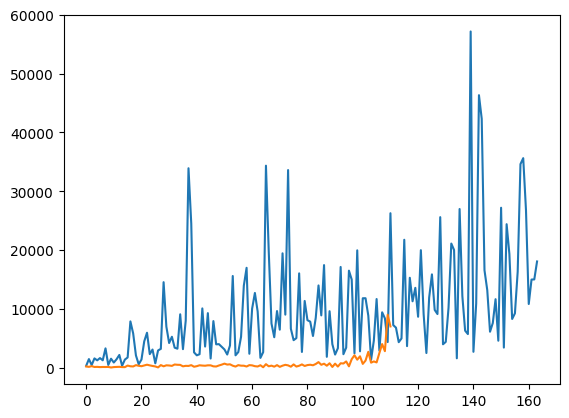

In [388]:
plt.plot(error_grads_norm)
plt.plot(error_grad_norm4)

$\textbf{Multitask:}$

$H=50$

In [386]:
H_tasks = 50
eta = 2.5e-5

indices = random.sample(range(1, H), H_tasks-1)

As_tasks = [As[0]]
Bs_tasks = [Bs[0]]
Qs_tasks = [Qs[0]]
Rs_tasks = [Rs[0]]
for h in range(len(indices)):
    As_tasks.append(As[indices[h]])
    Bs_tasks.append(Bs[indices[h]])
    Qs_tasks.append(Qs[indices[h]])
    Rs_tasks.append(Rs[indices[h]])

K_H50,srs_multitask_H50,gammas_multitask_H50, Ks_H50, error_grad_norm4 = find_stabilizing_hd(As_tasks,Bs_tasks,Qs_tasks,Rs_tasks,gamma,N,r,ns,eta,xi, ns_cost)

Iteration: 0, Spectral radius: 1.5293425390964788, gamma: 0.2
219.04032680653242
-----
cost: 4.470756394548302
-----
-----
min alpha =0.07881106699911768, avg alpha = 0.12241043896805186
-----
Iteration: 1, Spectral radius: 1.5296211899728167, gamma: 0.20788110669991178
155.4271531643334
-----
cost: 4.578934221450676
-----
-----
min alpha =0.08793409647970135, avg alpha = 0.11993484464592069
-----
Iteration: 2, Spectral radius: 1.529314968898763, gamma: 0.21702102534634035
273.51472105496913
-----
cost: 4.698473542524978
-----
-----
min alpha =0.08281888504995465, avg alpha = 0.11341476554657406
-----
Iteration: 3, Spectral radius: 1.5244939544803489, gamma: 0.22600774502213128
134.71908204081814
-----
cost: 4.833054566338072
-----
-----
min alpha =0.07808082182883858, avg alpha = 0.11199561008023534
-----
Iteration: 4, Spectral radius: 1.5214522760049973, gamma: 0.2348311802576366
150.6594516304616
-----
cost: 4.976013955464541
-----
-----
min alpha =0.06957807211455515, avg alpha = 0

-----
cost: 9.70234541692837
-----
-----
min alpha =0.03129618333060462, avg alpha = 0.052785484881432296
-----
Iteration: 40, Spectral radius: 1.2157168167247705, gamma: 0.4983041597543212
270.2008107727368
-----
cost: 9.842388099555068
-----
-----
min alpha =0.03821951844342529, avg alpha = 0.05446888657290465
-----
Iteration: 41, Spectral radius: 1.2007162265271043, gamma: 0.5078266322664041
419.4558872863806
-----
cost: 10.133966342213927
-----
-----
min alpha =0.03415340287111793, avg alpha = 0.05182689379931938
-----
Iteration: 42, Spectral radius: 1.1957424979254336, gamma: 0.5164986360466429
372.6834792648137
-----
cost: 10.282203058304137
-----
-----
min alpha =0.033046105652947355, avg alpha = 0.05083106888671849
-----
Iteration: 43, Spectral radius: 1.1863201331908717, gamma: 0.5250327702948432
343.46136102843127
-----
cost: 10.498084165329722
-----
-----
min alpha =0.03643630062105413, avg alpha = 0.049758044553003915
-----
Iteration: 44, Spectral radius: 1.1737587405876337

-----
min alpha =0.02290565015692061, avg alpha = 0.030963278721277493
-----
Iteration: 79, Spectral radius: 0.9936068542997044, gamma: 0.8492508355418392
304.64504406837506
-----
cost: 17.541544532861707
-----
-----
min alpha =0.018418535293821793, avg alpha = 0.029710316675949634
-----
Iteration: 80, Spectral radius: 0.9947619533525693, gamma: 0.8570718137857067
454.9679115417581
-----
cost: 18.047433029103942
-----
-----
min alpha =0.02002642526651698, avg alpha = 0.028332222332593755
-----
Iteration: 81, Spectral radius: 0.9952823419787972, gamma: 0.8656538560991155
512.354218755398
-----
cost: 18.628316817746665
-----
-----
min alpha =0.018211301876464116, avg alpha = 0.027004090071080514
-----
Iteration: 82, Spectral radius: 0.9955497032567125, gamma: 0.8735361979460886
422.50186010239486
-----
cost: 19.202949365803455
-----
-----
min alpha =0.019312597997471734, avg alpha = 0.025939882229754456
-----
Iteration: 83, Spectral radius: 0.9969107954693517, gamma: 0.881971324659675
64

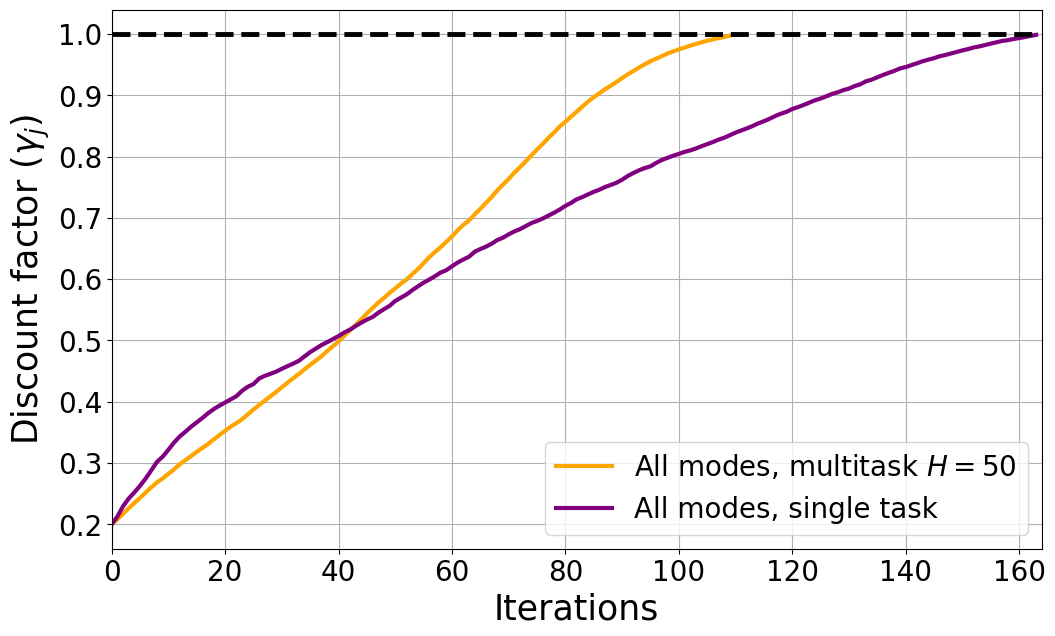

In [387]:
gamma_multitask_H50 = []

for i in range(len(gammas_multitask_H50)):
    if gammas_multitask_H50[i][0]<=1:
        gamma_multitask_H50.append(gammas_multitask_H50[i][0])
        

gamma_singletask = []

for i in range(len(gammas_singletask)):
    if gammas_singletask[i][0] <= 1:
        gamma_singletask.append(gammas_singletask[i][0])

plt.figure(figsize=(12,7)) 
plt.plot(gamma_multitask_H50, color='orange', label=r'All modes, multitask $H = 50$', linewidth=3)
plt.plot(gamma_singletask, color='purple', label='All modes, single task', linewidth=3)
plt.plot(np.arange(len(gamma_singletask)), np.ones(len(gamma_singletask)), linestyle='--', color='black', linewidth=3.5)
plt.xlim(0, len(gamma_singletask))
plt.ylabel(r'Discount factor $(\gamma_j)$',fontsize=25)
plt.xlabel('Iterations',fontsize=25)
plt.tick_params(axis='both', labelsize=20)
plt.legend(fontsize=20)
plt.grid()
plt.show()

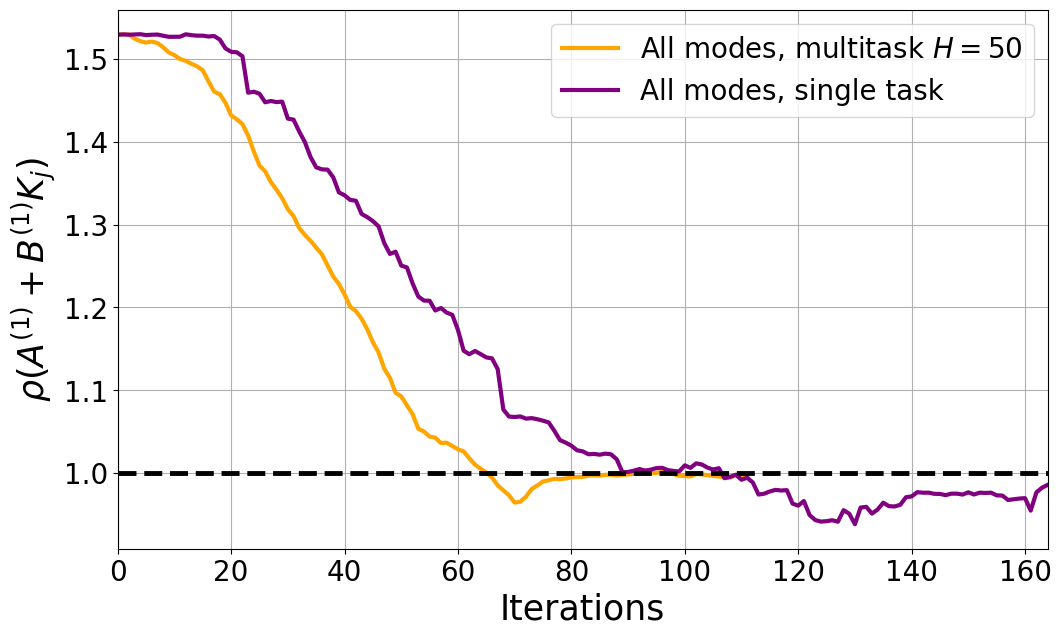

In [389]:
idx = 0

sr_multitask_H50 = []

for i in range(len(srs_multitask_H50)):
    sr_multitask_H50.append(srs_multitask_H50[i][idx])
    

sr_singletask = []

for i in range(len(srs_singletask)):
    sr_singletask.append(srs_singletask[i][0])


plt.figure(figsize=(12,7))
plt.plot(sr_multitask_H50, color='orange', label=r'All modes, multitask $H = 50$', linewidth=3)
plt.plot(sr_singletask, color='purple', label='All modes, single task', linewidth=3)
plt.plot(np.arange(len(sr_singletask)), np.ones(len(sr_singletask)), linestyle='--', color='black', linewidth=3.5)
plt.xlim(0, len(gamma_singletask))
plt.ylabel(r'$\rho(A^{(1)}+B^{(1)}K_{j})$',fontsize=25)
plt.xlabel('Iterations',fontsize=25)
plt.tick_params(axis='both', labelsize=20)
plt.legend(fontsize=20)
plt.grid()
plt.show()

$\textbf{Learning on a shared subspace:}$

In [390]:
def find_stabilizing_ld(As,Bs,Qs,Rs,gamma,N,r,ns,eta,xi,ns_cost,Phi, As_original, Bs_original):
    
    H = len(As)
    dx = As[0].shape[0]
    du = Bs[0].shape[1]
    K = np.zeros((du,dx))
    sr = []
    Sigma_0 = np.eye(dx)
    
    
    gammas = []
    k = 0
    
    gamma_h = [gamma]*H
    sr.append(spectral_radius_mt(As_original,Bs_original,K@Phi.T))
    flag = 0
    
    Ks = [K.copy()]
    while flag == 0:
        
        
        gammas.append(gamma_h.copy())
        
        print(f"Iteration: {k}, Spectral radius: {max(sr[-1])}, gamma: {min(gammas[-1])}")
        K_l = K
        for n in range(N):
            grad_avg = gradient_avg_zo2p(As, Bs, Qs, Rs, K_l, r, ns, gamma_h)
            K_l=K_l - eta*grad_avg
        K = K_l
        
        
        #Update the discount factor
        alphas = []
        gammas_copy = gamma_h.copy()
        gammas_h = gamma_h.copy()
        for h in range(H):
            sigma_min_h = min(abs(la.eigvals(Qs[h] + K.T@Rs[h]@K)))
            alpha_h = sigma_min_h/(2*cost_gamma(As[h], Bs[h], Qs[h], Rs[h], K, gamma_h[h],ns_cost) - sigma_min_h)
            gammas_h[h] = (1+alpha_h*xi)*gammas_h[h]
            alphas.append(alpha_h)
            

        print("-----")
        print(f"min alpha = {min(alphas)}, avg alpha = {np.mean(alphas)}")
        print("-----")
           
            
        gamma_h_min = [(1+xi*min(alphas))*gamma_h[0]]*H
        gamma_h = gamma_h_min.copy()    
        
        
        Ks.append(K.copy)
        sr.append(spectral_radius_mt(As_original,Bs_original,K@Phi.T))  
        
        if min(gammas_h) >= 1:
            flag = 1
            gammas.append(gamma_h.copy())
            break
        
        k+=1
        
     
    return K, sr, gammas, Ks

$\textbf{Unstable Subspace:}$

In [391]:
def orth_complement(Phi):
    n, l = Phi.shape
    R = np.random.randn(n, n - l)
    R = R - Phi @ (Phi.T @ R)
    Phi_perp = orth(R)
    return Phi_perp

def subspace_distance(Phi1, Phi2):
    P1 = Phi1 @ Phi1.T
    P2 = Phi2 @ Phi2.T
    return norm(P1 - P2, 2)

def orth(A, rtol=1e-12):
    if A.size == 0:
        return A
    Q, R = np.linalg.qr(A)
    diag = np.abs(np.diag(R))
    rank = int(np.sum(diag > rtol * diag.max())) if diag.size else 0
    return Q[:, :rank]

def top_eigenvectors(Proj, l):
    """
    Returns the top l eigenvectors of matrix Proj as columns of Phi.
    """

    eigvals, eigvecs = np.linalg.eig(Proj)

    idx = np.argsort(np.abs(eigvals))[::-1]

    Phi = eigvecs[:, idx[:l]]

    return orth(Phi)

In [392]:
H_tasks = 50

As_tasks = []
Bs_tasks = []
Qs_tasks = []
Rs_tasks = []
for h in range(H_tasks):
    As_tasks.append(As[h])
    Bs_tasks.append(Bs[h])
    Qs_tasks.append(Qs[h])
    Rs_tasks.append(Rs[h])

In [393]:
Phis = []
Proj = np.zeros((d0,d0))
for h in range(H_tasks):
    eigvals_A, eigvecs = np.linalg.eig(As[h].T)
    unstable_idx = np.where(np.abs(eigvals_A) >= 1.0)[0]
    Phis.append(orth(np.real(eigvecs[:, unstable_idx])))
    Proj+=(1/H_tasks)*(Phis[-1]@Phis[-1].T)

$\textbf{Ground-truth shared subspace:}$

In [395]:
Phi_shared = top_eigenvectors(Proj, l)
subspace_distance(Phi_shared, Phis[0])
#math.degrees(math.asin(subspace_distance(Phi_shared, Phis[1])))

np.float64(0.014726148749934385)

$\textbf{Learning the representation:}$

In [396]:
"""
Adjoint sampling via simulation of the original system, using PyTorch autodiff (backprop).
"""
from __future__ import annotations
import math
from dataclasses import dataclass
from typing import Callable, Optional, Tuple

import torch

Tensor = torch.Tensor


def set_seed(seed: int = 0) -> None:
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def as_vector(x: Tensor) -> Tensor:
    """Ensure 1D tensor."""
    if x.ndim == 1:
        return x
    if x.ndim == 2 and (x.shape[0] == 1 or x.shape[1] == 1):
        return x.view(-1)
    raise ValueError(f"Expected a vector, got shape {tuple(x.shape)}")


# ----------------------------
# Primal rollout
# ----------------------------

@torch.no_grad()
def rollout_primal(
    f: Callable[[Tensor], Tensor],
    x0: Tensor,
    T: int,
) -> Tensor:
    """
    Forward rollout:
        x_{t+1} = f(x_t)
    Returns:
        X: (T+1, d)
    """
    x = as_vector(x0).detach()
    xs = [x]
    for _ in range(T):
        x = as_vector(f(x)).detach()
        xs.append(x)
    return torch.stack(xs, dim=0)

# ----------------------------
# Adjoint sampling via autodiff
# ----------------------------

def vjp_autodiff(
    f: Callable[[Tensor], Tensor],
    x: Tensor,
    v: Tensor,
) -> Tensor:
    """
    Compute J_f(x)^T v using autodiff without forming J_f.

    Implementation:
      g(x) = v^T f(x)
      grad_x g = J_f(x)^T v
    """
    x = as_vector(x).detach().clone().requires_grad_(True)
    v = as_vector(v).detach()

    y = as_vector(f(x))
    g = torch.dot(v, y)

    # Helpful diagnostics
    if not g.requires_grad:
        raise RuntimeError()

    (grad_x,) = torch.autograd.grad(g, x, retain_graph=False, create_graph=False)
    return grad_x.detach()


def rollout_adjoint_from_primal(
    f: Callable[[Tensor], Tensor],
    X: Tensor,
    vT: Tensor,
) -> Tensor:
    if X.ndim != 2:
        raise ValueError("X must be shape (T+1, d)")
    T = X.shape[0] - 1
    d = X.shape[1]

    v = as_vector(vT).detach()
    if v.numel() != d:
        raise ValueError(f"vT has dim {v.numel()} but X has d={d}")

    V = [None] * (T + 1)
    V[T] = v

    for t in reversed(range(T)):
        x_t = X[t]
        v = vjp_autodiff(f, x_t, v)
        V[t] = v

    return torch.stack(V, dim=0)


# ----------------------------
# Simulator
# ----------------------------

def make_linear_f(A: Tensor) -> Callable[[Tensor], Tensor]:
    """f(x) = A x (differentiable; uses torch matmul)."""
    def f(x: Tensor) -> Tensor:
        dx = x.shape[0]
        w = 0.1 * torch.randn(dx, dtype=x.dtype, device=x.device)
        return A @ as_vector(x) + w
    return f

In [403]:
Phis_hat = []
Proj_hat = torch.zeros(d0,d0)

for h in range(H_tasks):

    A = torch.from_numpy(As[h]).to(torch.float32)
    f = make_linear_f(A)

    T = 25 #horizon length
    x0 = torch.randn(d0)
    vT = torch.randn(d0)
    X = rollout_primal(f, x0, T)  # (T+1, d)
    D = rollout_adjoint_from_primal(f, X, vT)
 
    D_arr = np.zeros((d0,T+1))
    for t in range(T+1):
        D_arr[:, t] = D[T - t, :].detach().cpu().numpy()
    
    U, S, Vt = np.linalg.svd(D_arr, full_matrices=False)
    Phi_hat = torch.from_numpy(U[:, :l]).float()
    Phis_hat.append(Phi_hat)

    Proj_hat+=(1/H_tasks)*(Phis_hat[-1]@Phis_hat[-1].T)
    
Proj_hat =  Proj_hat.numpy()
Phi_shared_hat = top_eigenvectors(Proj_hat, l)
subspace_distance(Phi_shared, Phi_shared_hat)

np.float64(0.008609496197503038)

In [404]:
subspace_distance(Phi_shared_hat, Phis[0])

np.float64(0.010914537664557243)

In [405]:
Aus = []
Bus = []
Qus = []
Rus = []


Phi_shared_hat = Phi_shared.copy()

for h in range(H_tasks):
    Aus.append(Phi_shared_hat.T@As[h]@Phi_shared_hat)
    Bus.append(Phi_shared_hat.T@Bs[h])
    Qus.append(Phi_shared_hat.T@Qs[h]@Phi_shared_hat)
    Rus.append(Rs[h])

In [406]:
gamma = 0.2
ns = 5
r = 0.1
N = 3
xi = 0.5
ns_cost = 50

Aus_tasks = []
Bus_tasks = []
Qus_tasks = []
Rus_tasks = []
for h in range(H_tasks):
    Aus_tasks.append(Aus[h])
    Bus_tasks.append(Bus[h])
    Qus_tasks.append(Qus[h])
    Rus_tasks.append(Rus[h])

theta, srs_multitask_ld, gammas_multitask_ld,thetas = find_stabilizing_ld(Aus_tasks,Bus_tasks,Qus_tasks,Rus_tasks,gamma,N,r,ns,eta,xi, ns_cost, Phi_shared_hat, As_tasks,Bs_tasks)

Iteration: 0, Spectral radius: 1.6445032156240953, gamma: 0.2
-----
min alpha = 0.11043842476743104, avg alpha = 0.18300177626540126
-----
Iteration: 1, Spectral radius: 1.6416733897803781, gamma: 0.21104384247674313
-----
min alpha = 0.11344723909975615, avg alpha = 0.17007619998779222
-----
Iteration: 2, Spectral radius: 1.6383641086578193, gamma: 0.22301501310573832
-----
min alpha = 0.0844478347248078, avg alpha = 0.15791106147550382
-----
Iteration: 3, Spectral radius: 1.635885302705446, gamma: 0.23243158058969043
-----
min alpha = 0.09387759035012004, avg alpha = 0.1511205428076023
-----
Iteration: 4, Spectral radius: 1.63694726296425, gamma: 0.24334163894320535
-----
min alpha = 0.0833964301002841, avg alpha = 0.14393120234178144
-----
Iteration: 5, Spectral radius: 1.6321203468589895, gamma: 0.25348855093451317
-----
min alpha = 0.08407006680216299, avg alpha = 0.13686913241992527
-----
Iteration: 6, Spectral radius: 1.6310478341725896, gamma: 0.2641439506398372
-----
min alpha

-----
min alpha = 0.03598492279376733, avg alpha = 0.04926343517440919
-----
Iteration: 54, Spectral radius: 1.0437645637860542, gamma: 0.6712838425041189
-----
min alpha = 0.030192733331175583, avg alpha = 0.047577295264468404
-----
Iteration: 55, Spectral radius: 1.0393000100810832, gamma: 0.6814177895272459
-----
min alpha = 0.02583532564266426, avg alpha = 0.04840027658948899
-----
Iteration: 56, Spectral radius: 1.03368995637003, gamma: 0.6902201147728163
-----
min alpha = 0.029070204385201522, avg alpha = 0.04615658668673502
-----
Iteration: 57, Spectral radius: 1.0291340250175955, gamma: 0.7002525346764278
-----
min alpha = 0.023037681192961394, avg alpha = 0.04662456501109479
-----
Iteration: 58, Spectral radius: 1.0262607562815036, gamma: 0.7083186320006472
-----
min alpha = 0.028238180267453394, avg alpha = 0.044491690086422384
-----
Iteration: 59, Spectral radius: 1.0188119428401234, gamma: 0.7183194466092623
-----
min alpha = 0.029529022218995924, avg alpha = 0.045040830738

In [366]:
K_lifted = theta@Phi_shared_hat.T
K_lifted

array([[0.30847617, 0.79749193, 1.19011732]])

In [368]:
for h in range(H_tasks):
    print(max(abs(la.eigvals(As_tasks[h] - Bs_tasks[h]@K_lifted))))

0.9981424607252318
0.9932465002061992
0.9944126238166514
1.0014337703036589
1.00027986420923
1.0008682133845386
0.9978082065979554
1.0001861525595312
0.9995171677268534
1.0014483383657566
1.0009484953981715
1.001249506709456
1.0011085297038989
0.9986426680934422
1.0015152919909063
0.995252212471449
0.9945190229167595
0.9948531350005128
0.9967713933158799
0.998426107480702
0.9993443133108064
0.9972673225622573
1.0015298066649523
0.9982508581971179
0.988867294242052
0.9959077220974134
0.9995663484329573
0.9980104545592982
0.9953737814040453
0.9988553980375123
0.9949759123760759
1.0003957730513235
0.9927218154271026
1.0000104947408863
0.9971867947475164
0.9964291747592156
0.993312076411401
0.9984260583579928
0.9988005392712841
0.9993468451103853
0.9993766250258262
1.0003181187752848
0.9991267746793713
0.9999751837010776
0.9980433468278408
1.000115110664043
0.9978428137086328
0.9969058162711946
1.0008512090802002
1.0013986508275503


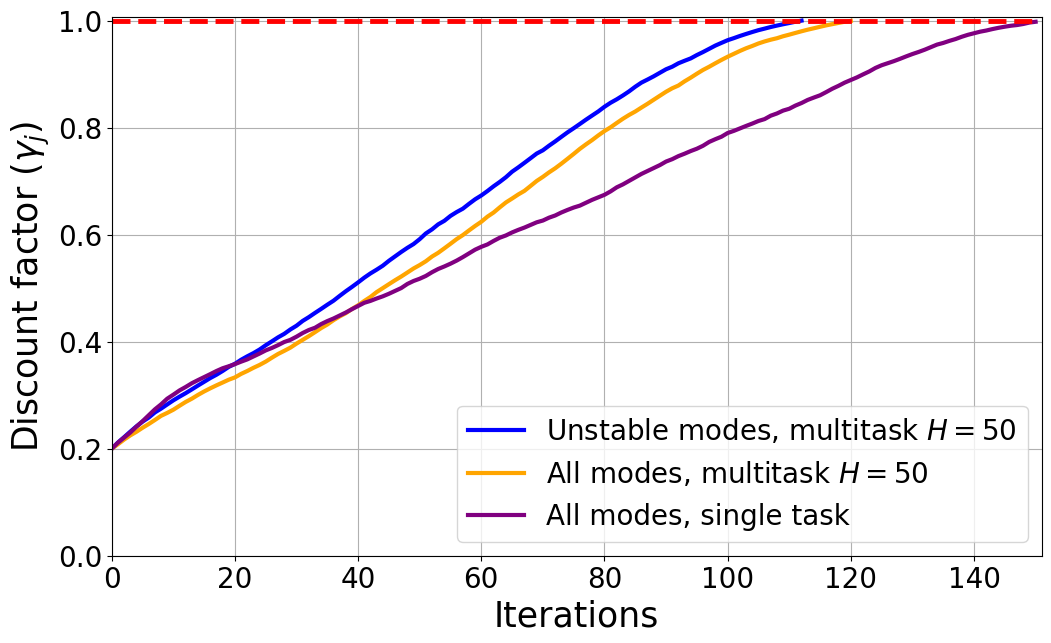

In [322]:
gamma_multitask_ld = []

for i in range(len(gammas_multitask_ld)):
    gamma_multitask_ld.append(gammas_multitask_ld[i][0])
    

plt.figure(figsize=(12,7))
plt.plot(gamma_multitask_ld, color='blue', label=r'Unstable modes, multitask $H = 50$', linewidth=3)
plt.plot(gamma_multitask_H50, color='orange', label=r'All modes, multitask $H = 50$', linewidth=3)
plt.plot(gamma_singletask, color='purple', label='All modes, single task', linewidth=3)
plt.plot(np.arange(len(gamma_singletask)), np.ones(len(gamma_singletask)), linestyle='--', color='red', linewidth=3.5)
plt.xlim(0, len(gamma_singletask))
plt.ylim(0, 1+0.75e-2)
plt.ylabel(r'Discount factor $(\gamma_j)$',fontsize=25)
plt.xlabel('Iterations',fontsize=25)
plt.tick_params(axis='both', labelsize=20)
plt.legend(fontsize=20)
plt.grid()
plt.show()

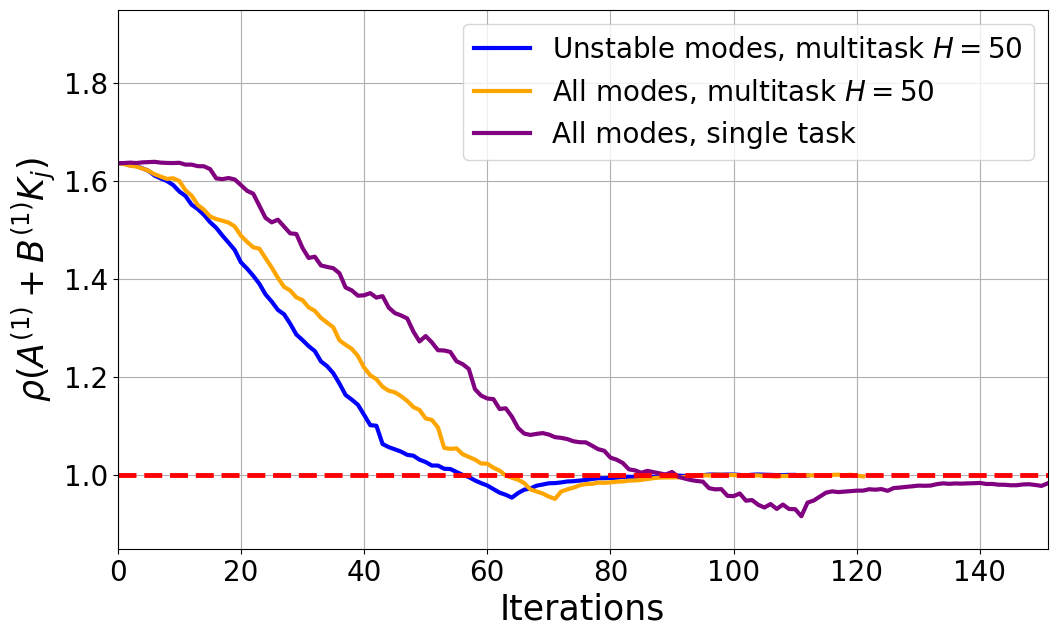

In [323]:
sr_multitask_ld = []

for i in range(len(srs_multitask_ld)):
    sr_multitask_ld.append(srs_multitask_ld[i][0])


plt.figure(figsize=(12,7))
plt.plot(sr_multitask_ld, color='blue', label=r'Unstable modes, multitask $H = 50$', linewidth=3)
plt.plot(sr_multitask_H50, color='orange', label=r'All modes, multitask $H = 50$', linewidth=3)
plt.plot(sr_singletask, color='purple', label='All modes, single task', linewidth=3)
plt.plot(np.arange(len(sr_singletask)), np.ones(len(sr_singletask)), linestyle='--', color='red', linewidth=3.5)
plt.xlim(0, len(gamma_singletask))
plt.ylim(0.85, 1.95)
plt.ylabel(r'$\rho(A^{(1)}+B^{(1)}K_{j})$',fontsize=25)
plt.xlabel('Iterations',fontsize=25)
plt.tick_params(axis='both', labelsize=20)
plt.legend(fontsize=20)
plt.grid()
plt.show()

In [291]:
def geometric_multiplicities_outside_unit_circle(A, tol=1e-8, group_tol=1e-6):
    """
    Return the geometric multiplicity of each eigenvalue of A
    with absolute value >= 1.

    Parameters
    ----------
    A : np.ndarray
        Square matrix.
    tol : float
        Tolerance used to determine numerical rank.
    group_tol : float
        Tolerance used to group nearly identical eigenvalues.

    Returns
    -------
    result : list of tuples
        Each tuple is (eigenvalue_representative, geometric_multiplicity).
    """
    A = np.asarray(A)
    n, m = A.shape
    if n != m:
        raise ValueError("A must be square.")

    eigvals = np.linalg.eigvals(A)

    # Keep only eigenvalues with abs(lambda) >= 1
    selected = [lam for lam in eigvals if abs(lam) >= 1 - group_tol]

    # Group numerically close eigenvalues together
    groups = []
    for lam in selected:
        placed = False
        for g in groups:
            if abs(lam - g[0]) < group_tol:
                g.append(lam)
                placed = True
                break
        if not placed:
            groups.append([lam])

    result = []
    I = np.eye(n, dtype=A.dtype)

    for g in groups:
        lam = sum(g) / len(g)  # representative
        M = A - lam * I
        rank = np.linalg.matrix_rank(M, tol=tol)
        gm = n - rank
        result.append((lam, gm))

    return result

In [258]:
geometric_multiplicities_outside_unit_circle(As_tasks[4])

[(np.float64(1.6075819846549602), np.int64(1)),
 (np.float64(1.0116050806959511), np.int64(1))]